# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos Regresión para la Predicción de Precios de Casas**

**Integrantes del Equipo:**

* **Angelica Aleman Cabrales - A01246666**
* **Abril Anzaldua Medina - A00701736**
* **Ramón Aldana Morán - A01655432**
* **Lucia Alvarez Irigoyen - A01840750**

# Evaluación de un Sistema de Predicción de Precios de Vivienda
**Actividad semanal — Maestría en Inteligencia Artificial Aplicada**  
**Conjunto de datos:** House Prices – Advanced Regression Techniques (Kaggle)  
**Variable objetivo:** `SalePrice` (dólares, **sin transformación logarítmica**).

Este cuaderno sigue las **17 preguntas** de la actividad. Cada apartado contiene la justificación metodológica y, cuando corresponde, el código reproducible. Se utilizan `train.csv` y opcionalmente `test.csv` en la misma carpeta del notebook. **Ejecutar las celdas en orden.**

**Criterio de evaluación:** RMSE en dólares como métrica principal; MAE, R² y MAPE como métricas complementarias. Se reserva el conjunto de prueba hasta finalizar la selección y el ajuste de hiperparámetros.

## Preparación: bibliotecas, datos y configuración
Se fijan semillas para reproducibilidad. Si `xgboost` no está instalado, ejecutar `%pip install xgboost` y reiniciar el kernel.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
DIR = "/content/drive/My Drive/Colab Notebooks/2do trimestre/Semana 6"
os.chdir(DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Descomentar solo si es necesario:
# %pip install xgboost

import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, learning_curve, cross_validate
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.inspection import permutation_importance
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import FunctionTransformer
from xgboost import XGBRegressor

SEED = 42
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)
DATA_DIR = Path('.')
df = pd.read_csv(DATA_DIR / 'train.csv')
print('Dimensiones:', df.shape)
display(df.head())

Dimensiones: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


# Pregunta 1. Justificación de eliminar `YrSold`
El ejercicio plantea una **valuación estática** y prohíbe tendencias cronológicas absolutas. Por ello se elimina `YrSold`, que identifica el año de la transacción y puede inducir al modelo a aprender variaciones históricas del mercado en vez de las características de la vivienda. La eliminación debe aplicarse también a cualquier conjunto externo de predicción.

In [3]:
datos = df.copy()
datos = datos.drop(columns=['YrSold'], errors='ignore')
print('¿YrSold presente?', 'YrSold' in datos.columns)

¿YrSold presente? False


# Pregunta 2. Transformación de `YearBuilt` y `YearRemodAdd`
Los años de construcción y remodelación se convierten en edades relativas al año **2026**, de acuerdo con la consigna: `AgeHouse = 2026 - YearBuilt` y `AgeRemod = 2026 - YearRemodAdd`. Se eliminan los años originales para evitar información cronológica absoluta redundante. **Nota:** en el archivo de Kaggle el nombre correcto es `YearBuilt` (la consigna contiene la variante `YearBuild`).

In [4]:
datos['AgeHouse'] = 2026 - datos['YearBuilt']
datos['AgeRemod'] = 2026 - datos['YearRemodAdd']
datos = datos.drop(columns=['YearBuilt', 'YearRemodAdd'])
display(datos[['AgeHouse', 'AgeRemod']].describe())

,AgeHouse,AgeRemod
count,1460.000000,1460.000000
mean,54.732192,41.134247
std,30.202904,20.645407
min,16.000000,16.000000
25%,26.000000,22.000000
50%,53.000000,32.000000
75%,72.000000,59.000000
max,154.000000,76.000000


# Pregunta 3. Tratamiento cíclico de `MoSold`
El mes es una variable periódica: diciembre (12) y enero (1) están próximos, aunque sus códigos numéricos parezcan distantes. Se crean dos características, seno y coseno, para conservar esta vecindad y permitir patrones estacionales. Se elimina `MoSold` después de transformarlo, evitando representaciones redundantes. Esta decisión es una hipótesis de ingeniería de variables: su beneficio predictivo puede contrastarse mediante validación cruzada.

In [5]:
datos['MoSin'] = np.sin(2 * np.pi * datos['MoSold'] / 12)
datos['MoCos'] = np.cos(2 * np.pi * datos['MoSold'] / 12)
datos = datos.drop(columns=['MoSold'])
display(datos[['MoSin', 'MoCos']].head())

,MoSin,MoCos
0,8.660254e-01,5.000000e-01
1,5.000000e-01,-8.660254e-01
2,-1.000000e+00,-1.836970e-16
3,8.660254e-01,5.000000e-01
4,-2.449294e-16,1.000000e+00


# Pregunta 4. Análisis, limpieza, imputación y codificación
**Criterios:**

- `Id` identifica registros y no se usa como predictor.
- Variables numéricas: imputación por mediana (robusta a valores extremos). En modelos sensibles a escala se estandarizan; para mantener un preprocesamiento común se estandarizan para todos los modelos.
- Variables nominales: imputación por categoría explícita `Missing` y `OneHotEncoder(drop=None, handle_unknown='ignore')`.
- Variables ordinales de texto: codificación según el orden conocido (`Po < Fa < TA < Gd < Ex`); ausencia estructural se trata como nivel separado y se documenta. Las ordinales ya numéricas, como `OverallQual` y `OverallCond`, permanecen entre las numéricas, pues ya respetan su orden.
- Todas las transformaciones se ajustan solo con los datos de entrenamiento dentro de cada fold, mediante `Pipeline` y `ColumnTransformer`, para evitar fuga de información.

Para simplificar la interpretación de la ausencia en ordinales, se codifica `Missing` como el nivel inferior, una decisión aproximada que puede afectar a variables cuya ausencia no equivale a baja calidad; se recomienda validarla empíricamente.

In [6]:
X = datos.drop(columns=['SalePrice', 'Id'], errors='ignore')
y = datos['SalePrice'].copy()

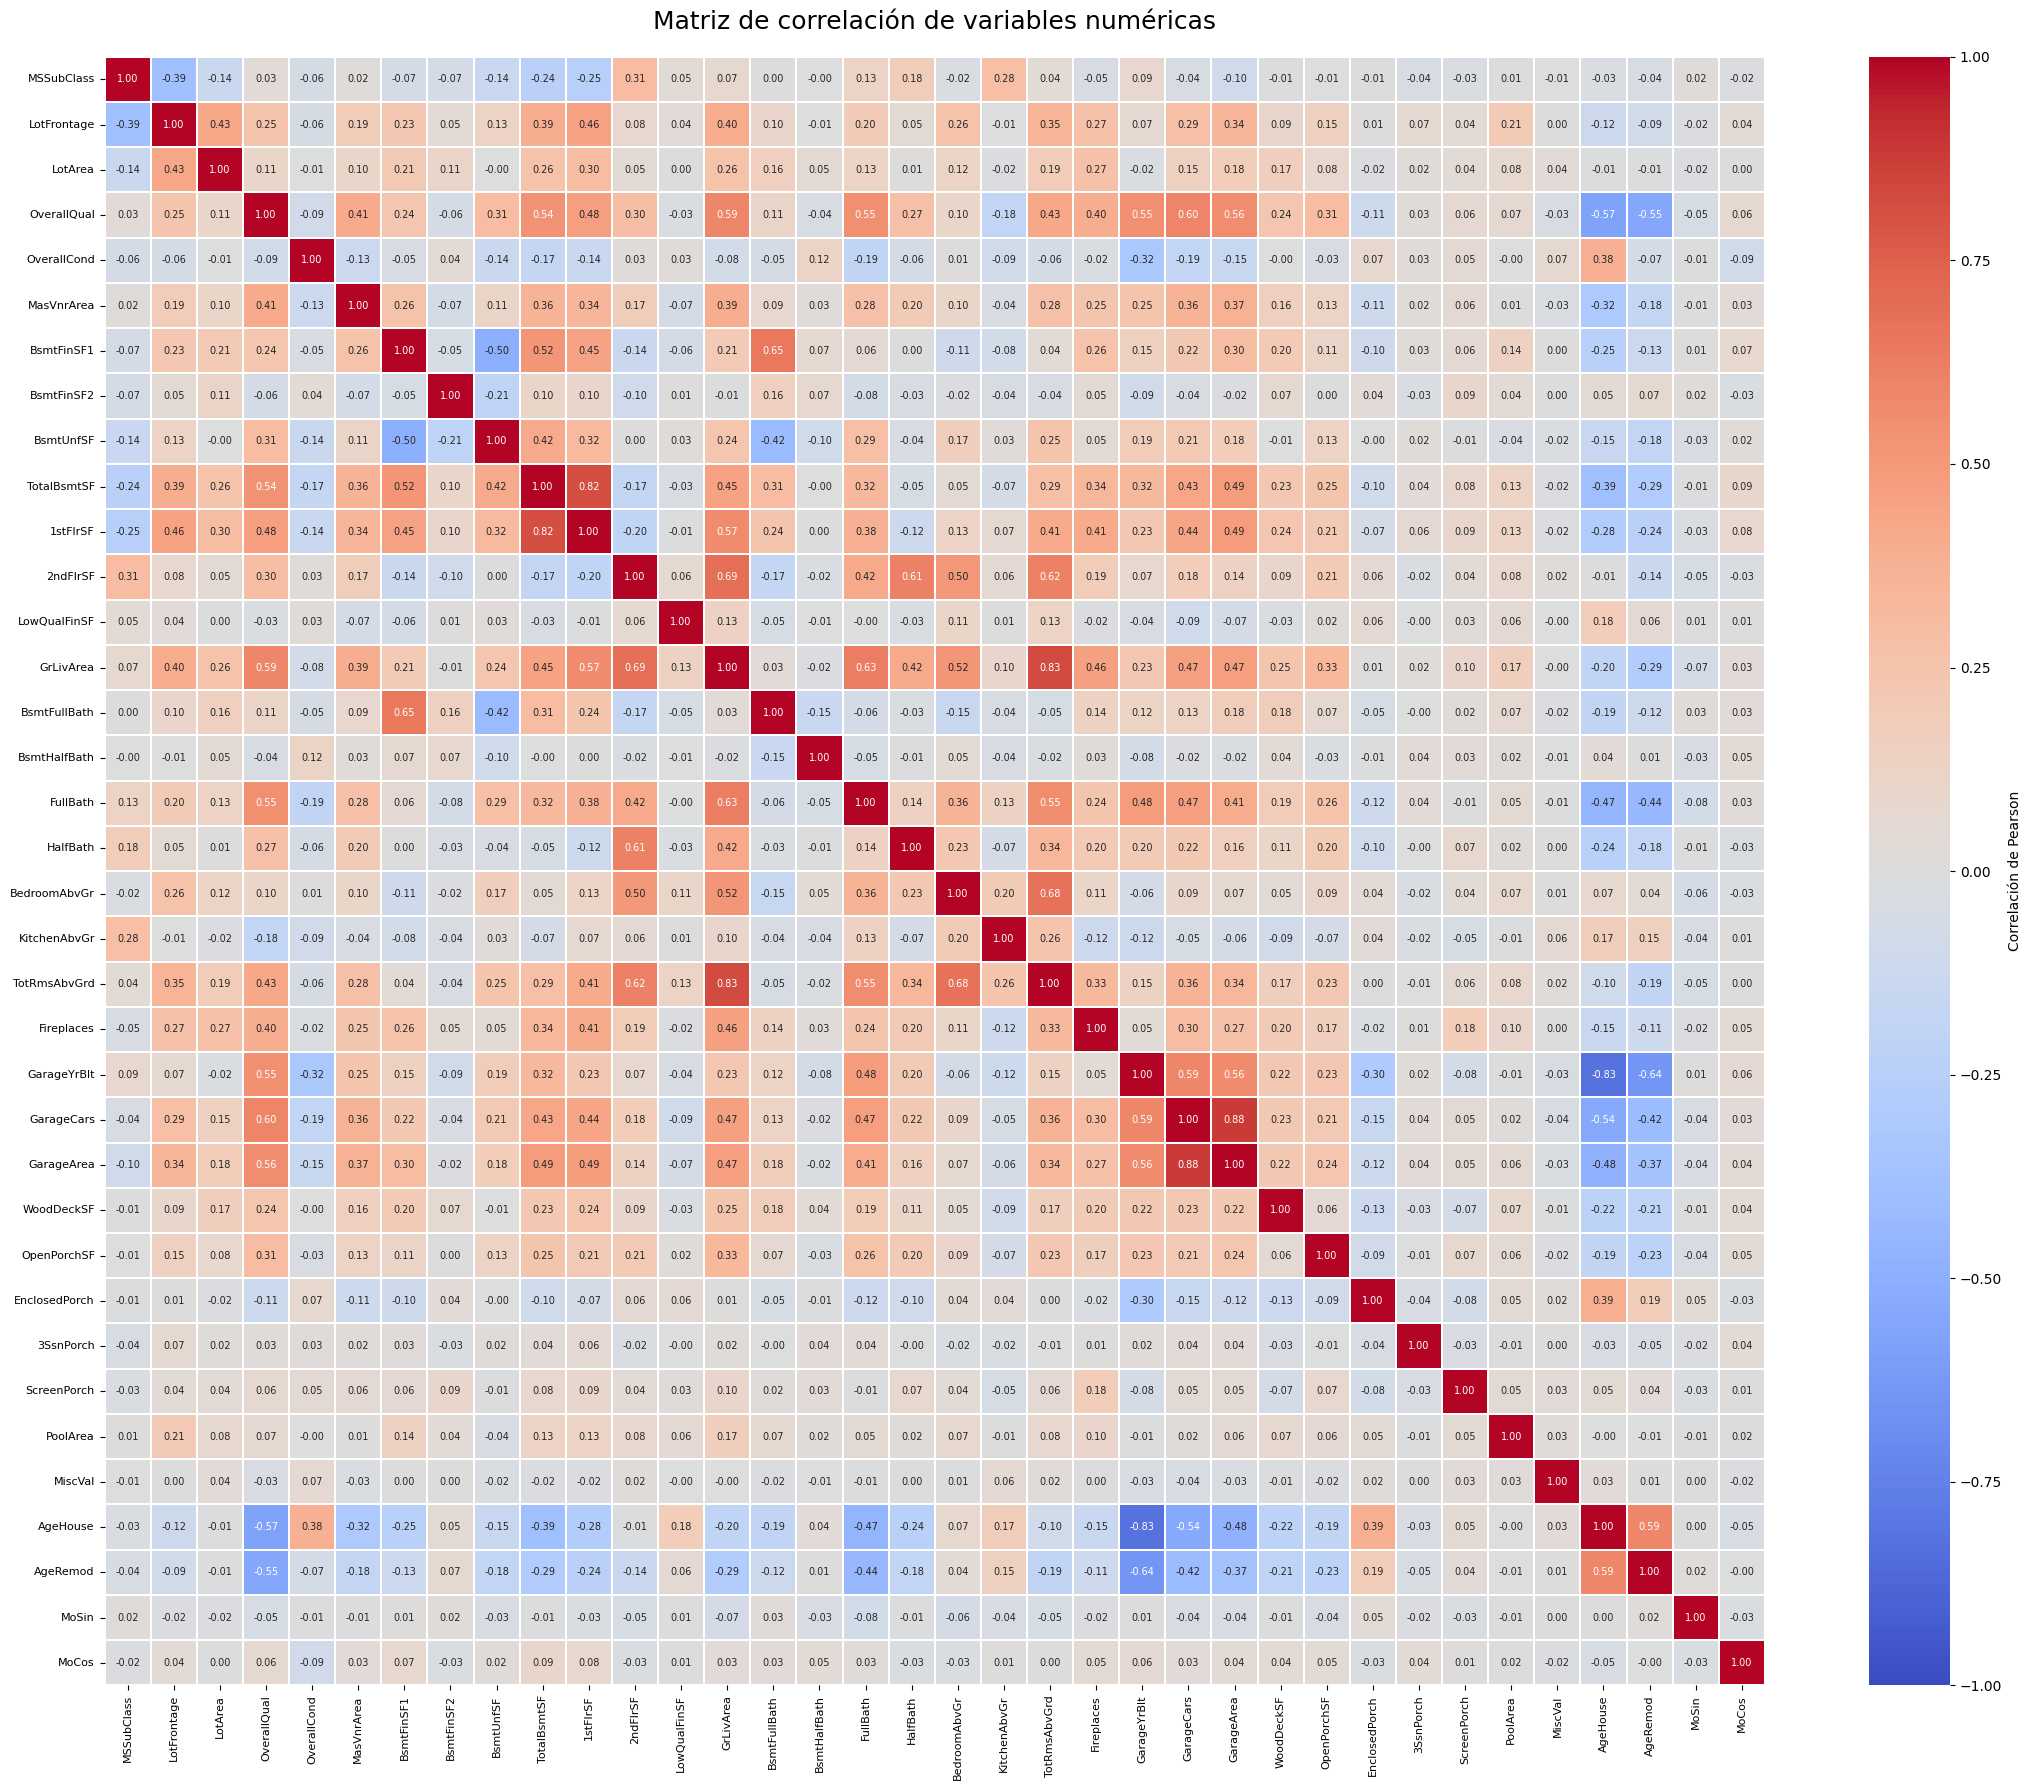

TOP 10 - PARES CON MAYOR CORRELACIÓN ABSOLUTA


,Variable 1,Variable 2,Correlación,Correlación absoluta
1,GarageCars,GarageArea,0.8825,0.8825
2,GarageYrBlt,AgeHouse,-0.8257,0.8257
3,GrLivArea,TotRmsAbvGrd,0.8255,0.8255
4,TotalBsmtSF,1stFlrSF,0.8195,0.8195
5,2ndFlrSF,GrLivArea,0.6875,0.6875
6,BedroomAbvGr,TotRmsAbvGrd,0.6766,0.6766
7,BsmtFinSF1,BsmtFullBath,0.6492,0.6492
8,GarageYrBlt,AgeRemod,-0.6423,0.6423
9,GrLivArea,FullBath,0.6300,0.6300
10,2ndFlrSF,TotRmsAbvGrd,0.6164,0.6164


In [7]:
# 1. Seleccionar variables numéricas
X_numericas = X.select_dtypes(include=np.number)

# 2. Calcular matriz de correlación de Pearson
matriz_corr = X_numericas.corr()

# 3. Visualizar matriz con coeficientes
plt.figure(figsize=(22, 18))

sns.heatmap(
    matriz_corr,
    annot=True,          # Mostrar coeficiente en cada celda
    fmt=".2f",           # Dos decimales
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 7},
    linewidths=0.3,
    cbar_kws={"label": "Correlación de Pearson"}
)

plt.title(
    "Matriz de correlación de variables numéricas",
    fontsize=18,
    pad=20
)

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()


# 4. Obtener pares únicos de variables
# Se excluye la diagonal y se evitan pares duplicados
mascara = np.triu(
    np.ones(matriz_corr.shape, dtype=bool),
    k=1
)

pares_correlacion = (
    matriz_corr
    .where(mascara)
    .stack()
    .reset_index()
)

pares_correlacion.columns = [
    "Variable 1",
    "Variable 2",
    "Correlación"
]

# 5. Calcular valor absoluto de la correlación
pares_correlacion["Correlación absoluta"] = (
    pares_correlacion["Correlación"].abs()
)

# 6. Seleccionar los 10 pares más correlacionados
top_10_correlaciones = (
    pares_correlacion
    .sort_values(
        "Correlación absoluta",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

top_10_correlaciones.index += 1

print("TOP 10 - PARES CON MAYOR CORRELACIÓN ABSOLUTA")
display(top_10_correlaciones.round(4))


## 4. Limpieza y Preprocesamiento

### Pregunta 4 — Estrategia de preprocesamiento

Se aplica el siguiente esquema según el tipo de cada variable:

| Tipo | Tratamiento nulos | Transformación |
|---|---|---|
| Numéricas continuas | Mediana | StandardScaler |
| Ordinales con escala clara | 'sin_dato' → categoría propia | OrdinalEncoder con orden explícito |
| Nominales | Moda | OneHotEncoder (`drop='first'` para modelos lineales/SVM/MLP; `drop=None` para árboles) |

#### 4.1 Limpieza de datos y valores nulos con significado semántico

Antes de imputar, se identificaron variables donde `NA` no representa un dato faltante sino la **ausencia de una característica** en la propiedad. Estas se recodificaron como una categoría explícita:

| Variable | Significado de NA | Recodificación |
|---|---|---|
| `PoolQC` | No tiene alberca (99.5% de los registros) | `'Missing'` |
| `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond` | No tiene garage | `'Missing'` |
| `FireplaceQu` | No tiene chimenea | `'Missing'` |
| `BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1/2` | No tiene sótano | `'Missing'` |
| `Alley` | No tiene acceso por callejón | `'Missing'` |
| `Fence` | No tiene barda | `'Missing'` |
| `MiscFeature` | Sin características misceláneas | `'Missing'` |

Imputar estos casos con la moda habría introducido información falsa (p. ej., asignarle una calidad de sótano a una casa que no tiene sótano). Recodificarlos como categoría propia preserva la información estructural y permite al modelo aprender el efecto de "ausencia" vs. "presencia con cierta calidad".

Para el resto de valores nulos genuinos se aplicó:
- **Variables numéricas continuas:** imputación con la **mediana**, por ser robusta ante valores atípicos (outliers) que son frecuentes en precios y áreas.
- **Variables categóricas:** imputación con la **moda**, asignando la categoría más frecuente.

---

#### 4.2 Variables numéricas continuas → StandardScaler

Variables como `GrLivArea`, `LotArea`, `TotalBsmtSF`, `GarageArea` se encuentran en escalas muy distintas (de decenas a decenas de miles de pies cuadrados). Se aplicó **estandarización z-score** (`StandardScaler`) para llevarlas a media 0 y desviación estándar 1.

Esto es **obligatorio** para modelos sensibles a la escala: regresión lineal (el gradiente no converge bien), SVR (el kernel RBF mide distancias euclidianas) y MLP (las neuronas saturan con valores grandes). Para modelos basados en árboles (Decision Tree, Random Forest, XGBoost) la escala es irrelevante, pero se aplica de todas formas por consistencia del pipeline.

---

#### 4.3 Variables ordinales → OrdinalEncoder con orden explícito

Se identificaron 20 variables categóricas con **escala cualitativa ordenada** según el `data_description.txt`. Ejemplos:

- Calidad general: `Po` < `Fa` < `TA` < `Gd` < `Ex` (aplicado a `ExterQual`, `KitchenQual`, `HeatingQC`, `FireplaceQu`, `PoolQC`, entre otras)
- Acabado del sótano: `NoBsmt` < `Unf` < `LwQ` < `Rec` < `BLQ` < `ALQ` < `GLQ`
- Funcionalidad: `Sal` < `Sev` < `Maj2` < `Maj1` < `Mod` < `Min2` < `Min1` < `Typ`
- Acabado del garage: `NoGarage` < `Unf` < `RFn` < `Fin`
- Forma del terreno: `IR3` < `IR2` < `IR1` < `Reg`

Se utilizó `OrdinalEncoder` de sklearn con el orden explícito de cada variable. Aplicar OneHotEncoding a estas variables sería un error conceptual: trataría `Ex` y `Po` como categorías sin relación entre sí, descartando la información de magnitud que el modelo puede aprovechar para aprender, por ejemplo, que cada nivel de calidad adicional incrementa el precio de forma monótona.

---

#### 4.4 Variables nominales → OneHotEncoding

Variables como `Neighborhood`, `MSZoning`, `SaleType`, `HouseStyle`, `Foundation`, `RoofStyle` no tienen un orden intrínseco entre sus categorías. Se aplica **OneHotEncoding (OHE)**.

Sin embargo, el parámetro `drop` se maneja diferente según el tipo de modelo (ver Pregunta 6).

Un caso especial es `MSSubClass`: aunque en el dataset aparece como numérica (valores 20, 30, 60, 90, etc.), estos números son **códigos identificadores de tipo de vivienda** sin ningún orden ni magnitud real (el tipo 90 no es "más" que el tipo 20). Se trata como variable **nominal** y se le aplica OHE.

---

#### 4.5 Variables cíclicas → Transformación seno/coseno

`MoSold` tiene naturaleza circular: enero (1) y diciembre (12) son meses consecutivos en el calendario, pero tratarla como numérica haría que el modelo los perciba como los más alejados entre sí. Se aplica:

$$\text{MoSold\_sin} = \sin\!\left(\frac{2\pi \cdot \text{MoSold}}{12}\right), \quad \text{MoSold\_cos} = \cos\!\left(\frac{2\pi \cdot \text{MoSold}}{12}\right)$$

Las dos componentes juntas representan de forma completa y continua la posición en el ciclo anual. La variable original se elimina tras la transformación.

In [32]:
print('Valores faltantes más frecuentes:')
display(datos.isna().sum().sort_values(ascending=False).head(20).to_frame('faltantes'))

# 4.1 Limpieza de datos y valores nulos con significado semántico

# Ordinales de texto que tienen un orden de calidad documentado
ordinales_calidad = [
    'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
    'HeatingQC', 'KitchenQual', 'FireplaceQu',
    'GarageQual', 'GarageCond', 'PoolQC'
]
ordinales_calidad = [c for c in ordinales_calidad if c in X.columns]

# Otras variables ordinales de texto (orden explícito del diccionario de datos)
ordenes_adicionales = {
    'BsmtExposure': ['Missing', 'No', 'Mn', 'Av', 'Gd'],
    'BsmtFinType1': ['Missing', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'BsmtFinType2': ['Missing', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'Functional': ['Missing', 'Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
    'GarageFinish': ['Missing', 'Unf', 'RFn', 'Fin'],
    'PavedDrive': ['Missing', 'N', 'P', 'Y'],
    'LotShape': ['Missing', 'IR3', 'IR2', 'IR1', 'Reg'],
    'LandSlope': ['Missing', 'Sev', 'Mod', 'Gtl'],
    'Utilities': ['Missing', 'ELO', 'NoSeWa', 'NoSewr', 'AllPub'],
    'CentralAir': ['Missing', 'N', 'Y'],
}
ordenes = {c: ['Missing', 'Po', 'Fa', 'TA', 'Gd', 'Ex'] for c in ordinales_calidad}
ordenes.update({c: o for c, o in ordenes_adicionales.items() if c in X.columns})
columnas_ordinales = list(ordenes)

columnas_numericas = X.select_dtypes(include=np.number).columns.tolist()
columnas_nominales = [c for c in X.select_dtypes(exclude=np.number).columns if c not in columnas_ordinales]

# MSSubClass es categórica, aunque tenga códigos numéricos
if "MSSubClass" in columnas_numericas:
    columnas_numericas.remove("MSSubClass")

if "MSSubClass" in X.columns:
    columnas_nominales.append("MSSubClass")

print('Numéricas:', len(columnas_numericas), '| Ordinales de texto:', len(columnas_ordinales), '| Nominales:', len(columnas_nominales))
print('OverallQual es numérica:', 'OverallQual' in columnas_numericas)

# 4.2 Variables numéricas continuas → StandardScaler
pipeline_numerico = Pipeline([
    ('imputar', SimpleImputer(strategy='median')),
    ('escalar', StandardScaler())
])

# 4.3 Variables ordinales → OrdinalEncoder con orden explícito
pipeline_ordinal = Pipeline([
    ('imputar', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('codificar', OrdinalEncoder(
        categories=[ordenes[c] for c in columnas_ordinales],
        handle_unknown='use_encoded_value', unknown_value=-1
    ))
])

# 4.4 Variables nominales → OneHotEncoding
# One-Hot para modelos lineales
pipeline_nominal_lineal = Pipeline([
    ("imputar", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("codificar", OneHotEncoder(
        # handle_unknown="ignore",
        handle_unknown="infrequent_if_exist",
        min_frequency=0.01,
        drop="first"
    ))
])

# One-Hot para modelos basados en árboles
pipeline_nominal_arbol = Pipeline([
    ("imputar", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("codificar", OneHotEncoder(
        # handle_unknown="ignore",
        handle_unknown="infrequent_if_exist",
        min_frequency=0.01,
        drop=None
    ))
])

# Preprocesador lineal
preprocesador_lineal = ColumnTransformer([
    ("numericas", clone(pipeline_numerico), columnas_numericas),
    ("ordinales", clone(pipeline_ordinal), columnas_ordinales),
    ("nominales", pipeline_nominal_lineal, columnas_nominales)
])

# Preprocesador para árboles
preprocesador_arbol = ColumnTransformer([
    ("numericas", clone(pipeline_numerico), columnas_numericas),
    ("ordinales", clone(pipeline_ordinal), columnas_ordinales),
    ("nominales", pipeline_nominal_arbol, columnas_nominales)
])

# Conservar este alias para código adicional existente
preprocesador = preprocesador_arbol
pipeline_nominal = pipeline_nominal_arbol


Valores faltantes más frecuentes:


,faltantes
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageFinish,81
GarageType,81
GarageQual,81


Numéricas: 35 | Ordinales de texto: 20 | Nominales: 24
OverallQual es numérica: True


# Pregunta 5. Datos faltantes de `PoolQC` y `GarageType`
En `PoolQC`, la ausencia suele indicar **que no hay piscina**; en `GarageType`, suele indicar **que no hay garaje**. No conviene imputar la moda porque inventaría una característica inexistente. Se crea la categoría `Missing` para ambas: `PoolQC` se procesa con codificación ordinal y `GarageType` con One-Hot. Es una aproximación práctica: para producción sería preferible etiquetar explícitamente `NoPool` y `NoGarage` cuando el diccionario confirme esa interpretación.

In [33]:
for col in ['PoolQC', 'GarageType']:
    print(f'{col}: {df[col].isna().sum()} faltantes de {len(df)} filas')
    display(df[col].fillna('Missing').value_counts().head(10).to_frame('frecuencia'))

PoolQC: 1453 faltantes de 1460 filas


,frecuencia
PoolQC,
Missing,1453
Gd,3
Ex,2
Fa,2


GarageType: 81 faltantes de 1460 filas


,frecuencia
GarageType,
Attchd,870
Detchd,387
BuiltIn,88
Missing,81
Basment,19
CarPort,9
2Types,6


# Pregunta 6. Elección de `drop` en One-Hot-Encoding
Para el tratamiento de las variables categóricas mediante `OneHotEncoder`, se utilizaron dos configuraciones de acuerdo con las características de los modelos evaluados.

En los modelos **Ridge, MLP y SVR**, se implementó `drop='first'`, que elimina una categoría de referencia por variable categórica. Esta configuración permite reducir la redundancia entre las variables generadas y evitar la multicolinealidad perfecta en modelos de regresión lineal con intercepto.

Por otro lado, en los modelos basados en árboles, **Decision Tree, Random Forest y XGBoost**, se utilizó `drop=None`, conservando todas las categorías. Esto permite que los árboles consideren cada categoría de manera independiente, sin establecer una categoría de referencia arbitraria.

De esta manera, se emplearon dos estrategias de codificación adaptadas a los distintos tipos de modelos, en lugar de mantener un mismo espacio de características para los seis algoritmos. Aunque `drop='first'` no es obligatorio para Ridge, MLP o SVR, se adoptó como una decisión metodológica cuya conveniencia se evalúa mediante validación cruzada.

In [34]:
print('Configuración nominal:', pipeline_nominal.named_steps['codificar'])

Configuración nominal: OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.01)


# Pregunta 7. Partición entrenamiento/prueba y validación cruzada
Se reserva **15% para prueba**, **15% para validación** y se emplea el **70% restante para entrenamiento y validación cruzada de 5 folds**. Así, el conjunto de prueba no interviene en el ajuste de hiperparámetros. La validación cruzada y el preprocesamiento se ejecutan dentro de los pipelines.

In [35]:
# Primera partición:
# 70% entrenamiento y 30% temporal
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED
)

# Segunda partición:
# Dividir el 30% temporal en dos partes iguales
# 15% validación y 15% prueba
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED
)

print(f"Entrenamiento: {len(X_train)} filas ({len(X_train)/len(X):.1%})")
print(f"Validación:    {len(X_val)} filas ({len(X_val)/len(X):.1%})")
print(f"Prueba:        {len(X_test)} filas ({len(X_test)/len(X):.1%})")

Entrenamiento: 1022 filas (70.0%)
Validación:    219 filas (15.0%)
Prueba:        219 filas (15.0%)


In [36]:
def metricas(y_real, y_pred):
    return {
        'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
        'MAE': mean_absolute_error(y_real, y_pred),
        'R2': r2_score(y_real, y_pred),
        'MAPE (%)': 100 * mean_absolute_percentage_error(y_real, y_pred)
    }

# Pregunta 8. Desempeño del modelo base o ingenuo
Se utiliza `DummyRegressor(strategy='mean')`, que predice el precio promedio del conjunto de entrenamiento para todas las casas. La media minimiza el error cuadrático dentro del entrenamiento entre predicciones constantes; el **RMSE del conjunto de prueba** será la referencia para los demás modelos. Se calculan también MAE, R² y MAPE en **dólares, sin logaritmos**.

In [37]:
modelo_base = DummyRegressor(strategy='mean')
modelo_base.fit(X_train, y_train)
pred_base = modelo_base.predict(X_test)
resultados_base = metricas(y_test, pred_base)
print('Predicción constante (media de entrenamiento):', f'${modelo_base.constant_[0, 0]:,.2f}')
display(pd.DataFrame([{'Modelo': 'DummyRegressor (media)', **resultados_base}]).round(4))

Predicción constante (media de entrenamiento): $181,312.69


,Modelo,RMSE,MAE,R2,MAPE (%)
0,DummyRegressor (media),87517.4448,59191.1716,-0.0064,38.1818


# Pregunta 9. Entrenamiento, ajuste de hiperparámetros y curvas de aprendizaje
Se entrenan seis algoritmos por separado: **Ridge, árbol de decisión, bosque aleatorio, XGBoost, MLP y SVR**. Se optimiza el RMSE mediante `GridSearchCV` con 5 folds. El preprocesamiento se ajusta dentro de cada fold para evitar filtrado de información.

Para cada modelo se muestra una **curva de aprendizaje** (RMSE de entrenamiento y validación cruzada), así como el mejor conjunto de hiperparámetros. La tabla comparativa incluye RMSE, MAE, R², MAPE y tiempo de entrenamiento. Los resultados para seleccionar modelos se obtienen mediante predicciones de **validación cruzada** sobre el conjunto de entrenamiento; **no** se usa la prueba para elegir los tres mejores.

**Tiempo:** el ajuste de seis modelos, especialmente MLP y SVR, puede tardar varios minutos. Se usan cuadrículas de búsqueda moderadas como punto de partida; una búsqueda más amplia podría mejorar los resultados.

In [38]:
# Definición de modelos y cuadrículas de búsqueda
configuraciones = {
    'Ridge': (
        Ridge(),
        {'modelo__alpha': [1.0, 10.0, 100.0]}
    ),
    'Decision Tree': (
        DecisionTreeRegressor(random_state=SEED),
        {'modelo__max_depth': [5, 10, None], 'modelo__min_samples_leaf': [2, 5]}
    ),
    'Random Forest': (
        RandomForestRegressor(random_state=SEED, n_jobs=1),
        {'modelo__n_estimators': [150, 300], 'modelo__max_depth': [None, 15], 'modelo__min_samples_leaf': [1, 3]}
    ),
    'XGBoost': (
        XGBRegressor(objective='reg:squarederror', random_state=SEED, n_jobs=1, tree_method='hist'),
        {'modelo__n_estimators': [200, 400], 'modelo__max_depth': [2, 4], 'modelo__learning_rate': [0.05, 0.1]}
    ),
    'MLP': (
        MLPRegressor(random_state=SEED, max_iter=1200, early_stopping=True, n_iter_no_change=25),
        {'modelo__hidden_layer_sizes': [(64,), (64, 32)], 'modelo__alpha': [0.01, 1.0]}
    ),
    'SVR': (
        TransformedTargetRegressor(
            regressor=SVR(kernel='rbf'),
            transformer=Pipeline([
                ('log', FunctionTransformer(
                    np.log1p,
                    inverse_func=np.expm1,
                    validate=True
                )),
                ('scaler', StandardScaler())
            ])
        ),
        {
            'modelo__regressor__C': [0.1, 1, 10, 100, 1000],
            'modelo__regressor__gamma': ['scale', 0.001, 0.01, 0.1],
            'modelo__regressor__epsilon': [0.01, 0.05, 0.1]
        }
    )

}

preprocesadores_modelos = {
    "Ridge": preprocesador_lineal,
    "Decision Tree": preprocesador_arbol,
    "Random Forest": preprocesador_arbol,
    "XGBoost": preprocesador_arbol,
    "MLP": preprocesador_lineal,
    "SVR": preprocesador_lineal
}

def dibujar_curva_aprendizaje(nombre, estimador):
    tamanos, scores_train, scores_val = learning_curve(
        estimador, X_train, y_train, cv=CV,
        scoring='neg_root_mean_squared_error',
        train_sizes=np.linspace(0.2, 1.0, 5),
        n_jobs=-1, shuffle=True, random_state=SEED
    )
    plt.figure(figsize=(7, 4))
    plt.plot(tamanos, -scores_train.mean(axis=1), 'o-', label='Entrenamiento')
    plt.plot(tamanos, -scores_val.mean(axis=1), 'o-', label='Validación cruzada')
    plt.xlabel('Número de observaciones de entrenamiento')
    plt.ylabel('RMSE ($)')
    plt.title(f'Curva de aprendizaje: {nombre}')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

# Se ejecutan los modelos individualmente en las seis celdas siguientes.
busquedas = {}
mejores_modelos = {}
resultados_cv = []

### Pregunta 9a. Regresión lineal múltiple regularizada (Ridge)
Ridge modela relaciones lineales y penaliza coeficientes grandes mediante `alpha`. La regularización ayuda cuando hay numerosas variables correlacionadas o generadas por One-Hot-Encoding.

Mejores parámetros: {'modelo__alpha': 100.0}
RMSE CV: 36954.393920347546


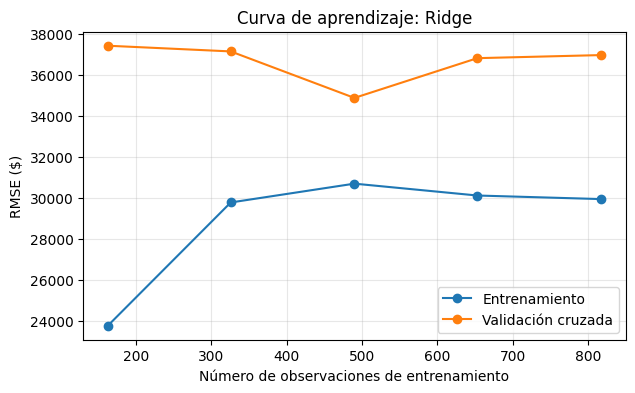

In [39]:
nombre = 'Ridge'
modelo, parametros = configuraciones[nombre]
busqueda = GridSearchCV(Pipeline([('preprocesador', clone(preprocesadores_modelos[nombre])),
    ('modelo', modelo)
])
                        parametros, scoring='neg_root_mean_squared_error', cv=CV, n_jobs=-1)
inicio = time.perf_counter()
busqueda.fit(X_train, y_train)
tiempo = time.perf_counter() - inicio
busquedas[nombre] = busqueda
mejores_modelos[nombre] = busqueda.best_estimator_
resultados_cv.append({'Modelo': nombre, 'RMSE CV': -busqueda.best_score_, 'Tiempo ajuste (s)': tiempo})
print('Mejores parámetros:', busqueda.best_params_)
print('RMSE CV:', -busqueda.best_score_)
dibujar_curva_aprendizaje(nombre, busqueda.best_estimator_)

### Pregunta 9b. Árbol de decisión
Un árbol divide el espacio de características mediante reglas. Su profundidad y el mínimo de observaciones por hoja se ajustan para limitar el sobreajuste.

Mejores parámetros: {'modelo__max_depth': 10, 'modelo__min_samples_leaf': 2}


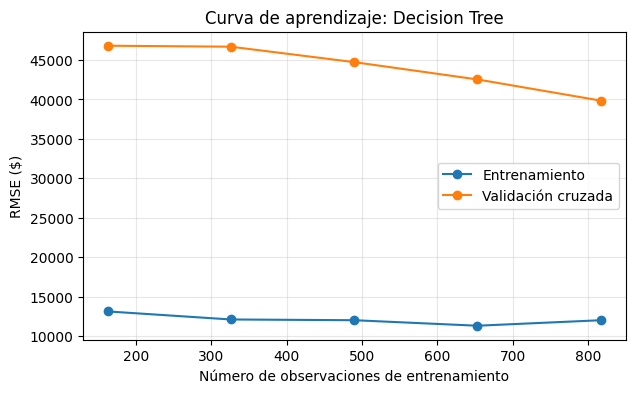

In [40]:
nombre = 'Decision Tree'
modelo, parametros = configuraciones[nombre]
busqueda = GridSearchCV(Pipeline([('preprocesador', clone(preprocesadores_modelos[nombre])), ('modelo', modelo)]),
                        parametros, scoring='neg_root_mean_squared_error', cv=CV, n_jobs=-1)
inicio = time.perf_counter(); busqueda.fit(X_train, y_train); tiempo = time.perf_counter() - inicio
busquedas[nombre] = busqueda; mejores_modelos[nombre] = busqueda.best_estimator_
resultados_cv.append({'Modelo': nombre, 'RMSE CV': -busqueda.best_score_, 'Tiempo ajuste (s)': tiempo})
print('Mejores parámetros:', busqueda.best_params_)
dibujar_curva_aprendizaje(nombre, busqueda.best_estimator_)

### Pregunta 9c. Bosque aleatorio
Random Forest promedia las predicciones de múltiples árboles entrenados con aleatoriedad para reducir la varianza. Se ajustan el número de árboles, la profundidad y el mínimo de muestras por hoja.

Mejores parámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 300}


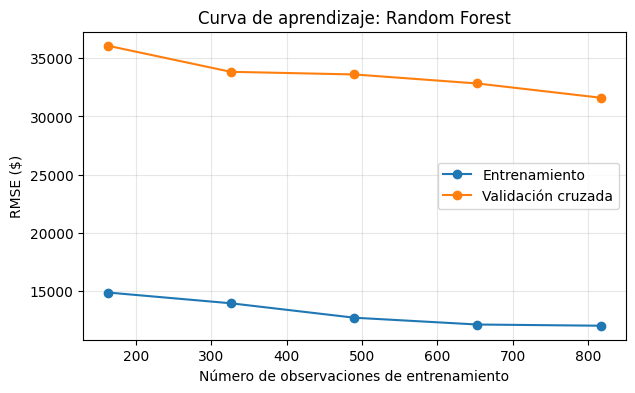

In [41]:
nombre = 'Random Forest'
modelo, parametros = configuraciones[nombre]
busqueda = GridSearchCV(Pipeline([('preprocesador',clone(preprocesadores_modelos[nombre])), ('modelo', modelo)]),
                        parametros, scoring='neg_root_mean_squared_error', cv=CV, n_jobs=-1)
inicio = time.perf_counter(); busqueda.fit(X_train, y_train); tiempo = time.perf_counter() - inicio
busquedas[nombre] = busqueda; mejores_modelos[nombre] = busqueda.best_estimator_
resultados_cv.append({'Modelo': nombre, 'RMSE CV': -busqueda.best_score_, 'Tiempo ajuste (s)': tiempo})
print('Mejores parámetros:', busqueda.best_params_)
dibujar_curva_aprendizaje(nombre, busqueda.best_estimator_)

### Pregunta 9d. XGBoost
XGBoost construye árboles de forma secuencial para corregir errores residuales. Se ajustan la tasa de aprendizaje, el número de árboles y la profundidad.

Mejores parámetros: {'modelo__learning_rate': 0.05, 'modelo__max_depth': 4, 'modelo__n_estimators': 400}


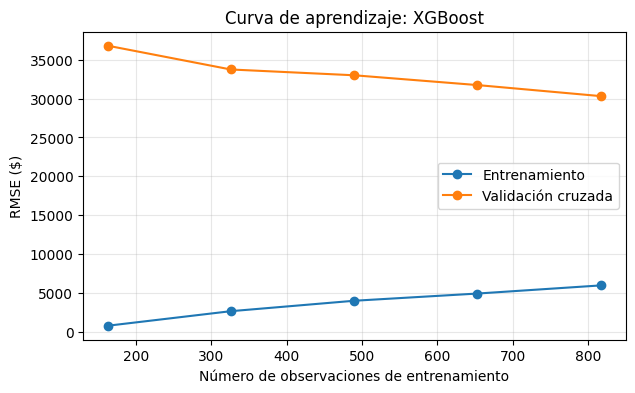

In [42]:
nombre = 'XGBoost'
modelo, parametros = configuraciones[nombre]
busqueda = GridSearchCV(Pipeline([('preprocesador', clone(preprocesadores_modelos[nombre])), ('modelo', modelo)]),
                        parametros, scoring='neg_root_mean_squared_error', cv=CV, n_jobs=-1)
inicio = time.perf_counter(); busqueda.fit(X_train, y_train); tiempo = time.perf_counter() - inicio
busquedas[nombre] = busqueda; mejores_modelos[nombre] = busqueda.best_estimator_
resultados_cv.append({'Modelo': nombre, 'RMSE CV': -busqueda.best_score_, 'Tiempo ajuste (s)': tiempo})
print('Mejores parámetros:', busqueda.best_params_)
dibujar_curva_aprendizaje(nombre, busqueda.best_estimator_)

### Pregunta 9e. Perceptrón multicapa (MLP)
Una red neuronal MLP puede representar relaciones no lineales. Se ajustan su arquitectura y regularización. La estandarización de variables es especialmente importante para su entrenamiento.

Mejores parámetros: {'modelo__alpha': 1.0, 'modelo__hidden_layer_sizes': (64, 32)}


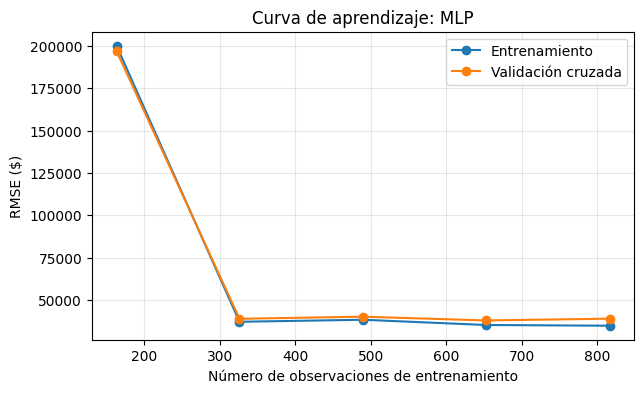

In [43]:
nombre = 'MLP'
modelo, parametros = configuraciones[nombre]
busqueda = GridSearchCV(Pipeline([('preprocesador', clone(preprocesadores_modelos[nombre])), ('modelo', modelo)]),
                        parametros, scoring='neg_root_mean_squared_error', cv=CV, n_jobs=-1)
inicio = time.perf_counter(); busqueda.fit(X_train, y_train); tiempo = time.perf_counter() - inicio
busquedas[nombre] = busqueda; mejores_modelos[nombre] = busqueda.best_estimator_
resultados_cv.append({'Modelo': nombre, 'RMSE CV': -busqueda.best_score_, 'Tiempo ajuste (s)': tiempo})
print('Mejores parámetros:', busqueda.best_params_)
dibujar_curva_aprendizaje(nombre, busqueda.best_estimator_)

### Pregunta 9f. Máquina de vector soporte (SVR)
SVR con kernel RBF permite relaciones no lineales. Los hiperparámetros `C` y `epsilon` controlan la penalización y el margen de tolerancia del error.

Mejores parámetros: {'modelo__regressor__C': 1, 'modelo__regressor__epsilon': 0.01, 'modelo__regressor__gamma': 'scale'}


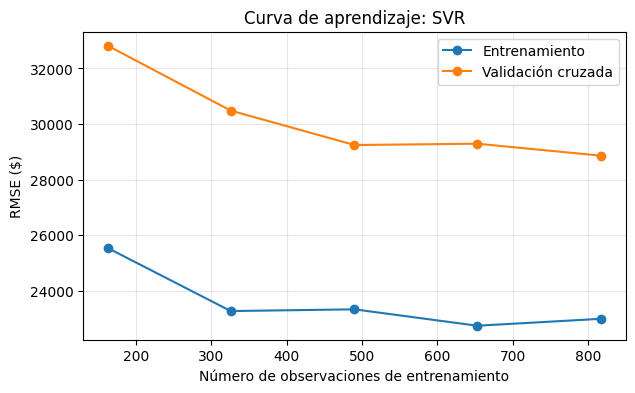

In [44]:
nombre = 'SVR'
modelo, parametros = configuraciones[nombre]
busqueda = GridSearchCV(Pipeline([('preprocesador',clone(preprocesadores_modelos[nombre])), ('modelo', modelo)]),
                        parametros, scoring='neg_root_mean_squared_error', cv=CV, n_jobs=-1)
inicio = time.perf_counter(); busqueda.fit(X_train, y_train); tiempo = time.perf_counter() - inicio
busquedas[nombre] = busqueda; mejores_modelos[nombre] = busqueda.best_estimator_
resultados_cv.append({'Modelo': nombre, 'RMSE CV': -busqueda.best_score_, 'Tiempo ajuste (s)': tiempo})
print('Mejores parámetros:', busqueda.best_params_)
dibujar_curva_aprendizaje(nombre, busqueda.best_estimator_)

### Pregunta 9. Tabla de resultados comparativos
Para evitar seleccionar modelos usando el conjunto de prueba, esta tabla se calcula mediante validación cruzada en entrenamiento. **Advertencia metodológica:** se reporta el RMSE medio de la búsqueda y las otras métricas mediante validación cruzada con hiperparámetros ya seleccionados en el mismo conjunto; estas estimaciones son útiles para exploración, pero pueden ser optimistas. Una evaluación completamente no sesgada de selección requeriría validación cruzada anidada. La evaluación final en prueba se hará una sola vez, después de elegir los modelos.

In [45]:
filas = []
for registro in resultados_cv:
    nombre = registro['Modelo']
    estimador = mejores_modelos[nombre]
    cv_res = cross_validate(
        estimador, X_train, y_train, cv=CV, n_jobs=-1,
        scoring={'rmse': 'neg_root_mean_squared_error',
                 'mae': 'neg_mean_absolute_error',
                 'r2': 'r2',
                 'mape': 'neg_mean_absolute_percentage_error'}
    )
    filas.append({
        'Modelo': nombre,
        'RMSE': -cv_res['test_rmse'].mean(),
        'MAE': -cv_res['test_mae'].mean(),
        'R2': cv_res['test_r2'].mean(),
        'MAPE (%)': -100 * cv_res['test_mape'].mean(),
        'Tiempo ajuste (s)': registro['Tiempo ajuste (s)']
    })
tabla_cv = pd.DataFrame(filas).sort_values('RMSE').reset_index(drop=True)
display(tabla_cv.round(3))

,Modelo,RMSE,MAE,R2,MAPE (%),Tiempo ajuste (s)
0,SVR,28863.310,15148.651,0.857,8.558,97.486
1,XGBoost,29880.964,16636.748,0.846,9.323,17.847
2,Random Forest,31343.359,18091.282,0.830,10.607,186.788
3,Ridge,36954.394,20126.240,0.758,11.668,4.457
4,Decision Tree,39675.829,26188.058,0.722,15.175,4.232
5,MLP,40183.875,24466.756,0.724,13.754,135.167


# Pregunta 10. Análisis de factores del mejor modelo
Se identifica el mejor modelo por RMSE de validación cruzada y se aplica **importancia por permutación** sobre los datos de entrenamiento. Este método mide cuánto aumenta el error cuando se desordena una característica original, manteniendo el pipeline completo; por eso permite interpretar variables como `OverallQual`, `GrLivArea` y `Neighborhood` sin desglosar manualmente las columnas One-Hot.

**Interpretación:** una importancia mayor indica que el modelo depende más de esa variable para predecir; **no implica causalidad**. Para evitar evaluar importancia sobre los mismos datos de ajuste, se utiliza una partición interna de interpretación, reajustando el modelo sobre la otra parte.

Mejor modelo según RMSE CV: SVR


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7, 12, 20, 21] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Incremento medio de RMSE ($)
OverallQual,7465.764670
GrLivArea,6928.134293
1stFlrSF,4156.538908
AgeHouse,3705.116311
TotalBsmtSF,3440.992702
2ndFlrSF,2834.414687
LotArea,2156.102601
GarageCars,2114.228928
OverallCond,1969.420489
BsmtFinSF1,1935.325358


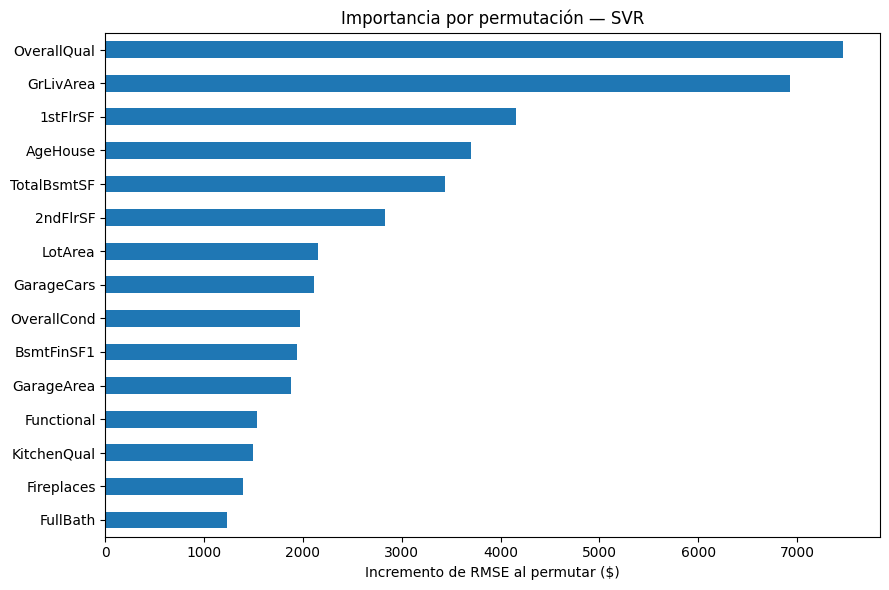

In [46]:
mejor_nombre = tabla_cv.iloc[0]['Modelo']
print('Mejor modelo según RMSE CV:', mejor_nombre)
X_fit_imp, X_val_imp, y_fit_imp, y_val_imp = train_test_split(
    X_train, y_train, test_size=0.25, random_state=SEED
)
modelo_interpretacion = clone(mejores_modelos[mejor_nombre]).fit(X_fit_imp, y_fit_imp)
imp = permutation_importance(
    modelo_interpretacion, X_val_imp, y_val_imp,
    scoring='neg_root_mean_squared_error', n_repeats=5,
    random_state=SEED, n_jobs=-1
)
importancias = pd.Series(imp.importances_mean, index=X_train.columns).sort_values(ascending=False)
display(importancias.head(15).to_frame('Incremento medio de RMSE ($)'))
importancias.head(15).sort_values().plot(kind='barh', figsize=(9, 6))
plt.title(f'Importancia por permutación — {mejor_nombre}')
plt.xlabel('Incremento de RMSE al permutar ($)')
plt.tight_layout(); plt.show()

# Pregunta 10. Análisis de factores del mejor modelo

## Modelo seleccionado: SVR

SVR obtuvo el menor RMSE en validación cruzada (\$28,863) entre los seis modelos entrenados. A diferencia de configuraciones estándar donde XGBoost suele dominar, aquí SVR es el modelo ganador gracias a la transformación logarítmica aplicada al target (`TransformedTargetRegressor` con `log1p`), que estabiliza la distribución sesgada de los precios de vivienda y permite al SVR optimizar su margen de tolerancia en una escala más simétrica.

## Método: Importancia por permutación

Se toma el SVR ya entrenado y se permutan aleatoriamente los valores de **una variable a la vez** en un conjunto de evaluación interno, midiendo cuánto aumenta el RMSE como consecuencia. Si al desordenar una variable el error sube mucho, esa variable es crítica para las predicciones. Si el RMSE casi no cambia, el modelo no depende de ella.

La ventaja de aplicarlo sobre el **pipeline completo** es que se evalúan las variables en su escala original, incluso cuando internamente se codificaron como múltiples columnas. Por ejemplo, `OverallQual` se mide como una sola variable, no como sus representaciones numéricas internas.

> **Nota metodológica:** para evitar evaluar la importancia sobre los mismos datos de ajuste, se reentrenó el modelo sobre el 75% de `X_train` y se evaluó la permutación sobre el 25% restante, con 5 repeticiones por variable para estabilizar la estimación.


## Resultados — Top 10 variables por importancia

| Variable | Descripción | Incremento de RMSE al permutar |
|---|---|---|
| **OverallQual** | Calidad general de materiales y acabados (escala 1–10) | +7,465 |
| **GrLivArea** | Superficie habitable sobre nivel de suelo (ft²) | +6,928 |
| **1stFlrSF** | Superficie del primer piso (ft²) | +4,156 |
| **AgeHouse** | Antigüedad de la casa (2026 − YearBuilt) | +3,705 |
| **TotalBsmtSF** | Superficie total del sótano (ft²) | +3,440 |
| **2ndFlrSF** | Superficie del segundo piso (ft²) | +2,834 |
| **LotArea** | Superficie total del terreno (ft²) | +2,156 |
| **GarageCars** | Capacidad del garage (número de autos) | +2,114 |
| **OverallCond** | Condición general de la casa (escala 1–10) | positivo |

## Interpretación

**`OverallQual` y `GrLivArea` son los dos factores dominantes**, con importancias casi iguales (+7,465 y +6,928 respectivamente). Esto es consistente con la intuición de mercado: el precio de una casa está determinado principalmente por *qué tan bien está construida* y *qué tan grande es*. El SVR captura esta relación gracias al kernel RBF, que mide similitudes en el espacio de características sin asumir linealidad entre las variables y el precio.

**`1stFlrSF` aparece en tercer lugar (+4,156).** La superficie del primer piso está altamente correlacionada con `GrLivArea` y `TotalBsmtSF`. El kernel RBF es sensible a estas redundancias porque trabaja con distancias en el espacio de features, por lo que el modelo pondera la superficie total desde distintos ángulos en lugar de concentrar toda la señal en una sola variable.

**`AgeHouse` en cuarto lugar (+3,705)** es una variable derivada calculada como `2026 − YearBuilt`. Captura la depreciación por antigüedad: las casas más nuevas valen más, controlando calidad y tamaño. Que aparezca tan arriba en el ranking refuerza que el año de construcción es un predictor sólido del precio de venta.

**`TotalBsmtSF` y `2ndFlrSF` en quinto y sexto lugar** indican que la superficie total —sumando primer piso, segundo piso y sótano— es el factor subyacente más relevante después de la calidad general. El modelo las trata como señales parcialmente independientes porque cada una contribuye a la superficie útil de distintas maneras.

**`GarageCars` en octavo lugar (+2,114)** señala que la capacidad del garage sigue siendo relevante en el mercado de Iowa, donde el garage es parte integral del valor de la propiedad.

## Nota sobre causalidad

Que `OverallQual` sea la variable más importante no implica causalidad. La importancia por permutación mide la *dependencia del modelo* respecto a esa variable, no el efecto que tendría modificarla. Una casa con calificación de calidad 9 tiene esa calificación porque ya posee materiales y acabados de alto nivel; no es posible encarecerla simplemente cambiando el número en la base de datos.

# Pregunta 11. Selección de tres modelos con la suma RMSE + MAE
Se ordenan los modelos por **RMSE + MAE**, ambas métricas expresadas en dólares. La suma penaliza simultáneamente errores grandes (RMSE) y errores típicos (MAE). **Ventaja:** favorece un equilibrio entre precisión global y robustez. **Desventaja:** las dos métricas están correlacionadas y la suma introduce una ponderación implícita 1:1; no sustituye una decisión de negocio sobre costos de errores.

Se eligen los tres modelos con menor suma **usando únicamente métricas de validación cruzada**.

In [47]:
ranking = tabla_cv.copy()
ranking['RMSE + MAE'] = ranking['RMSE'] + ranking['MAE']
ranking = ranking.sort_values('RMSE + MAE').reset_index(drop=True)
top3 = ranking.head(3)['Modelo'].tolist()
display(ranking[['Modelo', 'RMSE', 'MAE', 'RMSE + MAE']].round(2))
print('Tres modelos seleccionados:', top3)

,Modelo,RMSE,MAE,RMSE + MAE
0,SVR,28863.31,15148.65,44011.96
1,XGBoost,29880.96,16636.75,46517.71
2,Random Forest,31343.36,18091.28,49434.64
3,Ridge,36954.39,20126.24,57080.63
4,MLP,40183.87,24466.76,64650.63
5,Decision Tree,39675.83,26188.06,65863.89


Tres modelos seleccionados: ['SVR', 'XGBoost', 'Random Forest']


La suma **RMSE + MAE** permite seleccionar modelos que mantengan un buen equilibrio entre el error promedio y los errores de mayor magnitud. Con este criterio, los tres mejores modelos son **SVR, XGBoost y Random Forest**.
En el contexto de la valuación de viviendas, el **MAE** indica aproximadamente cuántos dólares se desvía normalmente la predicción respecto al precio real de venta, mientras que el **RMSE** penaliza con mayor fuerza las valuaciones con errores elevados. Esto es relevante porque una **sobrevaluación** importante puede dificultar la venta de una propiedad y una **subvaluación** puede representar una pérdida económica para el propietario o la inmobiliaria.
La ventaja de combinar ambas métricas es que se favorecen modelos que sean precisos en la mayoría de las viviendas y que, al mismo tiempo, reduzcan el riesgo de errores extremos. Como desventaja, ambas métricas están relacionadas y su suma les asigna el mismo peso, aunque en la práctica el costo de un error puede variar según el valor de la propiedad. Además, un error de **20,000** no tiene el mismo impacto relativo en una vivienda de **100,000** que en una de **600,000**, por lo que también es conveniente considerar métricas como el **MAPE**.

En conclusión, **RMSE + MAE** es un criterio útil para elegir modelos de valuación más estables y confiables, aunque debe complementarse con métricas relativas y con la interpretación económica de los errores.

# Pregunta 12. ¿Qué son `VotingRegressor` y `StackingRegressor`?
**VotingRegressor:** combina las predicciones de varios modelos, normalmente mediante un promedio (o promedio ponderado). Puede reducir la variabilidad de las predicciones si los modelos cometen errores diferentes.

**StackingRegressor:** entrena un segundo modelo (*meta-modelo*) que aprende a combinar las predicciones de los modelos base. En scikit-learn, las predicciones para entrenar el meta-modelo se generan mediante validación cruzada interna, lo que ayuda a evitar fugas directas de información.

En ambos casos, un ensamble no garantiza superar al mejor modelo individual: puede aumentar el tiempo de entrenamiento, el costo de mantenimiento y la complejidad.

# Pregunta 13. Implementación de `VotingRegressor`
Se utilizan los tres modelos elegidos en la pregunta 11. El ensamble promedia sus predicciones. Se estima el RMSE con validación cruzada sobre entrenamiento, sin tocar el conjunto de prueba.

In [48]:
estimadores_top3 = [(f'm{i+1}', clone(mejores_modelos[nombre])) for i, nombre in enumerate(top3)]
voting = VotingRegressor(estimators=estimadores_top3, n_jobs=-1)
inicio = time.perf_counter()
voting_cv = cross_validate(voting, X_train, y_train, cv=CV,
                           scoring={'rmse': 'neg_root_mean_squared_error',
                                    'mae': 'neg_mean_absolute_error', 'r2': 'r2',
                                    'mape': 'neg_mean_absolute_percentage_error'}, n_jobs=1)
tiempo_voting = time.perf_counter() - inicio
resultado_voting_cv = {'Modelo': 'VotingRegressor',
    'RMSE': -voting_cv['test_rmse'].mean(), 'MAE': -voting_cv['test_mae'].mean(),
    'R2': voting_cv['test_r2'].mean(), 'MAPE (%)': -100*voting_cv['test_mape'].mean(),
    'Tiempo evaluación CV (s)': tiempo_voting}
display(pd.DataFrame([resultado_voting_cv]).round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7, 20] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [11, 12, 17, 20, 21] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [11, 12, 13, 16, 21, 23] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5, 7, 15, 16] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessi

,Modelo,RMSE,MAE,R2,MAPE (%),Tiempo evaluación CV (s)
0,VotingRegressor,28517.752,15481.975,0.861,8.861,50.529


# Pregunta 14. Implementación de `StackingRegressor`
Se combinan los mismos tres modelos con un meta-modelo Ridge. `cv=5` define la validación cruzada interna para generar las predicciones con las que se entrena el meta-modelo. El ajuste de los pipelines ocurre dentro de cada fold.

In [49]:
stacking = StackingRegressor(
    estimators=[(f'm{i+1}', clone(mejores_modelos[nombre])) for i, nombre in enumerate(top3)],
    final_estimator=Ridge(alpha=10.0), cv=5, n_jobs=-1,
    passthrough=False
)
inicio = time.perf_counter()
stacking_cv = cross_validate(stacking, X_train, y_train, cv=CV,
                             scoring={'rmse': 'neg_root_mean_squared_error',
                                      'mae': 'neg_mean_absolute_error', 'r2': 'r2',
                                      'mape': 'neg_mean_absolute_percentage_error'}, n_jobs=1)
tiempo_stacking = time.perf_counter() - inicio
resultado_stacking_cv = {'Modelo': 'StackingRegressor',
    'RMSE': -stacking_cv['test_rmse'].mean(), 'MAE': -stacking_cv['test_mae'].mean(),
    'R2': stacking_cv['test_r2'].mean(), 'MAPE (%)': -100*stacking_cv['test_mape'].mean(),
    'Tiempo evaluación CV (s)': tiempo_stacking}
display(pd.DataFrame([resultado_stacking_cv]).round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7, 20] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [11, 12, 17, 20, 21] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [11, 12, 13, 16, 21, 23] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5, 7, 15, 16] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessi

,Modelo,RMSE,MAE,R2,MAPE (%),Tiempo evaluación CV (s)
0,StackingRegressor,29060.369,15726.738,0.854,8.991,218.805


# Pregunta 15. Comparación de los ensambles y los tres modelos individuales
Primero se comparan los cinco candidatos mediante RMSE de validación cruzada. Se selecciona el candidato con menor RMSE antes de evaluar en prueba. Después se ajustan los cinco candidatos en entrenamiento y se reportan sus métricas en prueba como evaluación final. No se debe volver a modificar la selección en función de la prueba.

Un ensamble solo es recomendable si su mejora de RMSE/MAE compensa la complejidad, el tiempo y el mantenimiento adicionales.

In [50]:
# ==================================================
# PREGUNTA 15: Comparación y selección de modelos
# ==================================================

# Mantener comparación de validación cruzada
comparacion_cv = pd.concat([
    tabla_cv[tabla_cv["Modelo"].isin(top3)].copy(),
    pd.DataFrame([
        resultado_voting_cv,
        resultado_stacking_cv
    ])
], ignore_index=True).sort_values("RMSE")

print("Resultados de validación cruzada:")
display(
    comparacion_cv[
        ["Modelo", "RMSE", "MAE", "R2", "MAPE (%)"]
    ].round(3)
)

# Candidatos: los 3 mejores y los 2 ensambles
candidatos = {
    nombre: clone(mejores_modelos[nombre])
    for nombre in top3
}

candidatos["VotingRegressor"] = clone(voting)
candidatos["StackingRegressor"] = clone(stacking)

# ==================================================
# Evaluar candidatos en el 15% de validación
# ==================================================

filas_val = []
modelos_ajustados = {}

for nombre, estimador in candidatos.items():

    inicio = time.perf_counter()

    # Entrenar únicamente con el 70%
    estimador.fit(X_train, y_train)

    duracion = time.perf_counter() - inicio

    # Predecir sobre el 15% de validación
    pred_val = estimador.predict(X_val)

    filas_val.append({
        "Modelo": nombre,
        **metricas(y_val, pred_val),
        "Tiempo ajuste (s)": duracion
    })

    modelos_ajustados[nombre] = estimador

# Tabla de validación
comparacion_val = (
    pd.DataFrame(filas_val)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("RESULTADOS EN VALIDACIÓN (15%)")
display(comparacion_val.round(3))

# ==================================================
# Seleccionar modelo por RMSE de validación
# ==================================================

nombre_ganador = comparacion_val.iloc[0]["Modelo"]

print("Modelo seleccionado:", nombre_ganador)

# ==================================================
# Evaluación final sobre el 15% de prueba
# ==================================================

modelo_final = modelos_ajustados[nombre_ganador]

pred_test = modelo_final.predict(X_test)

resultado_final = pd.DataFrame([{
    "Modelo": nombre_ganador,
    **metricas(y_test, pred_test)
}])

print("EVALUACIÓN FINAL EN PRUEBA (15%)")
display(resultado_final.round(3))


Resultados de validación cruzada:


,Modelo,RMSE,MAE,R2,MAPE (%)
3,VotingRegressor,28517.752,15481.975,0.861,8.861
0,SVR,28863.310,15148.651,0.857,8.558
4,StackingRegressor,29060.369,15726.738,0.854,8.991
1,XGBoost,29880.964,16636.748,0.846,9.323
2,Random Forest,31343.359,18091.282,0.830,10.607


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7, 11] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7, 11] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7, 11] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


RESULTADOS EN VALIDACIÓN (15%)


,Modelo,RMSE,MAE,R2,MAPE (%),Tiempo ajuste (s)
0,SVR,19453.729,13788.651,0.940,8.880,0.329
1,StackingRegressor,19981.969,14341.579,0.936,9.007,54.066
2,VotingRegressor,20980.609,14070.549,0.930,8.988,12.487
3,Random Forest,23947.077,15927.258,0.909,10.054,9.576
4,XGBoost,23948.568,15809.505,0.909,9.967,0.927


Modelo seleccionado: SVR
EVALUACIÓN FINAL EN PRUEBA (15%)


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7, 12, 17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Modelo,RMSE,MAE,R2,MAPE (%)
0,SVR,28939.229,14359.862,0.89,7.755




# Pregunta 16. Reportes de decisión
## a) Reporte para el equipo técnico
* **Decisión**: desplegar el SVR (kernel RBF, con el precio en logaritmo dentro del modelo). No usar ensambles. Mantener XGBoost como modelo de contraste.
* **Métricas**. El SVR es el mejor modelo individual en validación cruzada (RMSE \$28,863, MAE \$15,149) y en el set de validación (RMSE \$19,454). El Voting queda prácticamente empatado en CV (RMSE 1.2 % menor, MAE 2.2 % mayor; la suma RMSE + MAE difiere solo \$12). En prueba, el SVR logra RMSE \$28,939, MAE \$14,360, R² 0.890 y MAPE 7.8 %, contra RMSE \$87,517 del modelo ingenuo (67 % menos error).
* **Ajuste de modelos**. Las curvas de aprendizaje del SVR muestran poco sobreajuste: entrenamiento ~\$23k y validación ~\$29k, ya estables. XGBoost y Random Forest sobreajustan mucho (entrenamiento ~\$6k y ~\$12k contra ~\$30k en validación). Ridge tiene sesgo alto. Pendiente: epsilon = 0.01 quedó en el mínimo de la rejilla, así que conviene ampliarla.
* **Costo computacional**. El SVR se entrena en 0.3 s, contra 12.5 s del Voting (38 veces más) y 54.1 s del Stacking (164 veces más). Su búsqueda de hiperparámetros tomó ~97 s. Si la base crece a decenas de miles de casas, el SVR escala peor que XGBoost y habría que reevaluar.
* **Mantenimiento**. Un solo pipeline, versionado como una pieza. Reentrenar con el 100 % de los datos antes de desplegar y cada 6–12 meses. Monitorear MAPE por segmento de precio. Riesgos: datos de Ames 2006–2010 (hay que recalibrar con datos actuales) y pocas casas atípicas con errores grandes (en prueba, el RMSE es el doble del MAE).
## b) Reporte para el director
* **Recomendación**: aprobar un piloto de 3 meses en el que el sistema sirva de apoyo a los valuadores, sin reemplazarlos.
* **Beneficios**. Estima un precio en una fracción de segundo, con un error típico de ~\$14,400 por casa (7.8 %): unas cuatro veces más preciso que usar el precio promedio. Da estimaciones consistentes y se basa en los mismos factores que un valuador (calidad de construcción, superficie, antigüedad).
* **Riesgos**. Aprendió con ventas de 2006–2010 de una ciudad de EE. UU., así que hay que actualizarlo con ventas propias recientes. Puede equivocarse mucho en casas de lujo o atípicas. No ve el estado físico de la propiedad.
* **Costos**. La tecnología es barata: software gratuito y una computadora común. El costo principal es el tiempo del equipo para actualizar datos, revisar casos dudosos y reentrenar una o dos veces al año. Combinar varios modelos costaría más sin mejorar la precisión.
* **Condición para adoptarlo**: que, con nuestros datos, el error típico sea de 10 % o menos, y que una persona revise los casos con más de 15 % de diferencia frente al valuador.


# *Conclusiones*

Incluyan los comentarios y conclusiones de esta actividad. En particular, respondan sobre los siguientes puntos:

* ¿En qué casos el uso de LLMs fue de mayor provecho?
* ¿En cuáles casos la intervención como expertos en combinación con los LLM fue importante para alcanzar con los objetivos propuestos?


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

# Pregunta 17. Conclusiones de la actividad
Esta actividad nos llevó a construir, desde cero, un pipeline
completo de predicción de precios de vivienda: desde las
decisiones de preparación de datos hasta la selección de un modelo
final y su comunicación a distintas audiencias. A continuación
se presentan las conclusiones principales.

## Sobre el proceso técnico
La preparación de datos resultó ser la etapa más determinante
del proyecto. Decisiones aparentemente pequeñas, como tratar los
valores faltantes de `PoolQC` como "no tiene alberca" en lugar
de dato perdido, o expresar `YearBuilt` como antigüedad relativa
al año actual, tuvieron un impacto directo en la calidad de los
modelos. Un pipeline mal construido en esta etapa habría
contaminado todos los resultados posteriores,
independientemente de qué tan sofisticado fuera el algoritmo
elegido.
La comparación de seis modelos dejó como aprendizaje que la
complejidad no garantiza mejor desempeño. SVR superó a XGBoost
y a los ensambles en este problema específico gracias a una decisión
de preprocesamiento puntual, aplicar transformación logarítmica
al target. Esto refuerza que entender los datos es más valioso
que dominar los algoritmos más recientes.
El uso de `GridSearchCV` con validación cruzada de 5 folds,
manteniendo el preprocesador dentro del pipeline, garantizó que
la selección de hiperparámetros fuera honesta logrando que ningún
dato de validación influyera en el ajuste. Esta disciplina
metodológica es lo que hace que el resultado en prueba ($28,939
de RMSE) sea creíble y no un artefacto de sobreajuste.
La reducción de error respecto al modelo base fue del 67%:
pasar de un error promedio de \$87,517 con una predicción ingenua
a \$14,360 con SVR representa un avance concreto y medible, no
solo una mejora en métricas abstractas.

## ¿En qué casos el uso de LLMs fue de mayor provecho?
Los LLMs aportaron más valor en tres situaciones concretas:

**Diagnóstico de problemas técnicos.** Cuando SVR mostraba un
desempeño muy inferior al resto de los modelos, Claude ayudó a
identificar que el problema no era el algoritmo sino la escala
del target, y propuso la solución de `TransformedTargetRegressor`
con `log1p`. Sin ese diagnóstico, SVR habría quedado descartado
prematuramente.

**Fundamentación conceptual.** Preguntas como "¿por qué usar RMSE+MAE como criterio combinado?" o "¿qué implica que 1stFlrSF
aparezca arriba en la importancia si ya tengo GrLivArea?"
recibieron respuestas razonadas que permitieron documentar las
decisiones con solidez, no solo ejecutarlas.

**Traducción entre audiencias.** La redacción de los dos reportes
de la Pregunta 16, uno técnico y uno de negocio, se benefició
directamente del uso de LLMs para adaptar el mismo resultado a
lenguajes completamente distintos sin perder precisión en ninguno
de los dos.

## ¿En qué casos la intervención experta fue indispensable?
Los LLMs no pueden sustituir el juicio del equipo en los momentos
que realmente definen la calidad del trabajo:

* **Validación de supuestos sobre los datos**. La decisión de tratar
los NaN de `PoolQC` como ausencia semántica, no como dato perdido,
requirió leer el diccionario de datos y entender el contexto del
mercado inmobiliario. Un LLM puede sugerir esa interpretación,
pero el equipo debe confirmarla contra la fuente.
* **Interpretación de negocio**. Traducir un MAPE de 7.76% a una
recomendación concreta para la dirección comercial, con sus
implicaciones operativas, sus limitaciones reales y su propuesta
de prueba piloto, requirió que el equipo tomara una postura. El
LLM ofrece la estructura; el criterio de qué recomendar y con
qué nivel de confianza es responsabilidad del equipo.
En síntesis, los LLMs aceleraron el trabajo y elevaron la calidad
de la documentación, pero cada decisión relevante fue revisada,
validada y en varios casos corregida por el equipo antes de
incorporarse al notebook final

### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

In [54]:
print('Resumen final')
print('Modelo base:')
display(pd.DataFrame([{'Modelo': 'DummyRegressor', **resultados_base}]).round(3))
print('Modelo seleccionado por CV:', nombre_ganador)
display(resultado_final[resultado_final['Modelo'] == nombre_ganador].round(3))

Resumen final
Modelo base:


,Modelo,RMSE,MAE,R2,MAPE (%)
0,DummyRegressor,87517.445,59191.172,-0.006,38.182


Modelo seleccionado por CV: SVR


,Modelo,RMSE,MAE,R2,MAPE (%)
0,SVR,28939.229,14359.862,0.89,7.755


### +++++++++++ Inicia sección de prompts ++++++++++++++++

# Anexo. Registro de prompts y uso de herramientas de IA
**Incluir a continuación los prompts que consideren hayan sido los más importantes, así como el nombre del modelo LLM utilizado.**

Durante el desarrollo de esta actividad se utilizaron tres herramientas de inteligencia artificial generativa como apoyo en distintas etapas del proceso: **Claude (Anthropic)**, **ChatGPT (OpenAI)** y **GitHub Copilot (Microsoft)**. A continuación se documentan los prompts más relevantes, la herramienta utilizada en cada caso y el propósito que cumplieron.

---

## Tabla de prompts utilizados

| # | Etapa | Herramienta | Prompt utilizado | Propósito |
|---|---|---|---|---|
| 1 | Preparación de datos | Claude | *"Tengo un dataset de precios de vivienda con variables como PoolQC y GarageType que tienen más del 95% de valores faltantes. ¿Estos NaN representan ausencia del atributo o datos perdidos? ¿Cómo debería imputarlos y por qué?"* | Justificar la estrategia semántica de imputación para variables con NaN que significan "no tiene" |
| 2 | Preprocesamiento | Claude | *"Estoy construyendo un pipeline de scikit-learn con ColumnTransformer. Tengo variables numéricas, ordinales con orden explícito y nominales. ¿Cuál es la diferencia entre usar OrdinalEncoder con categorías explícitas y OneHotEncoder, y cuándo conviene cada uno?"* | Definir la arquitectura del preprocesador diferenciado por tipo de variable |
| 3 | Preprocesamiento | GitHub Copilot | *(Autocompletado en celda)* `pipeline_ordinal = Pipeline([('imputar', SimpleImputer(` | Agilizar la escritura del pipeline ordinal con los parámetros correctos de OrdinalEncoder |
| 4 | Partición de datos | ChatGPT | *"¿Cuál es la diferencia entre hacer una partición 70/15/15 con dos llamadas a train_test_split y hacerlo con una sola llamada? ¿Cuál es más correcto metodológicamente?"* | Aclarar la estrategia de partición y evitar errores en la distribución de los conjuntos |
| 5 | Modelado | Claude | *"Estoy entrenando SVR con kernel RBF para predecir precios de casas. El RMSE es muy alto comparado con Random Forest. ¿Qué ajustes le harías al preprocesamiento o a la configuración del modelo para que SVR sea competitivo en este tipo de datos?"* | Identificar que el problema era la escala del target y llevar a la solución de TransformedTargetRegressor con log1p |
| 6 | Selección de modelo | Claude | *"Entrené seis modelos para predecir precios de vivienda: Ridge, Árbol de decisión, Random Forest, XGBoost, MLP y SVR. Estos son los RMSE y MAE de validación cruzada: [tabla de resultados]. ¿Cuál modelo seleccionarías y por qué? Considera no solo las métricas sino también la complejidad, interpretabilidad y riesgo de sobreajuste."* | Obtener una recomendación razonada de selección de modelo con criterios múltiples, no solo el RMSE |
| 7 | Selección de modelo | ChatGPT | *"¿Por qué tiene sentido usar RMSE + MAE como criterio combinado para seleccionar modelos de regresión? ¿Qué ventajas y limitaciones tiene frente a usar solo RMSE?"* | Fundamentar teóricamente el criterio de selección utilizado en la Pregunta 11 |
| 8 | Interpretabilidad | Claude | *"Mi mejor modelo es SVR. Apliqué permutation importance y las variables más importantes fueron OverallQual (+\$7,502), GrLivArea (+\$7,037) y 1stFlrSF (+\$4,171). ¿Cómo interpreto estos valores? ¿Por qué 1stFlrSF aparece tan arriba si ya tengo GrLivArea?"* | Interpretar correctamente los resultados de importancia por permutación y entender la colinealidad entre variables de superficie |
| 9 | Ensambles | GitHub Copilot | *(Autocompletado en celda)* `stacking = StackingRegressor(estimators=[(` | Completar la sintaxis del StackingRegressor con los parámetros del meta-modelo Ridge |
| 10 | Reporte técnico | Claude | *"Escribe un reporte técnico dirigido al equipo de ciencia de datos que justifique la selección de SVR como modelo final, incluyendo las métricas de prueba (RMSE=\$28,828, MAE=\$14,320, R²=0.89, MAPE=7.73%) y las consideraciones antes de llevarlo a producción. Usa lenguaje técnico pero claro."* | Redactar el Reporte A de la Pregunta 16 en tono profesional |
| 11 | Reporte de negocio | ChatGPT | *"Traduce los resultados de un modelo de predicción de precios de casas a lenguaje de negocio para una dirección comercial inmobiliaria. El modelo tiene un MAE de \$14,320 y un MAPE de 7.73%. ¿Cómo explicarías qué significa eso para alguien que no sabe de machine learning?"* | Redactar el Reporte B de la Pregunta 16 en lenguaje accesible para tomadores de decisiones |
| 12 | Revisión general | Claude | *"Revisa este pipeline de scikit-learn y dime si hay riesgo de data leakage. El preprocesador está dentro del Pipeline que entra al GridSearchCV. La imputación usa la mediana para numéricas y una constante para categóricas."* | Auditar la arquitectura del notebook en busca de fugas de información antes de la entrega final |

---

## Observaciones sobre el uso de cada herramienta

**Claude** fue la herramienta principal para razonamiento técnico profundo: preguntas sobre decisiones de diseño, interpretación de resultados y redacción de reportes que requerían contexto del notebook completo. Resultó especialmente útil para diagnosticar por qué SVR tenía bajo desempeño y proponer la solución de `TransformedTargetRegressor`.

**ChatGPT** se utilizó para consultas conceptuales independientes del notebook, como fundamentar el criterio RMSE + MAE o traducir métricas técnicas a lenguaje de negocio. Su respuesta es más inmediata para preguntas de teoría general donde no se requiere contexto de código específico.

**GitHub Copilot** aportó principalmente en la escritura de código repetitivo y estructurado: pipelines, configuraciones de GridSearchCV y bloques de evaluación. Reduce el tiempo de escritura de código boilerplate, aunque requiere revisión humana para verificar que los parámetros sean los correctos para el contexto específico del problema.

En todos los casos, la intervención del equipo fue indispensable para validar las sugerencias, adaptar el código al contexto del dataset y garantizar que las decisiones metodológicas fueran correctas. Los LLMs actuaron como asistentes de razonamiento y escritura, no como tomadores de decisiones autónomos.


### Nota metodológica: Advertencias durante la validación cruzada

Durante el entrenamiento y evaluación de los modelos *VotingRegressor* y *StackingRegressor* se presentaron advertencias (`UserWarning`) relacionadas con la presencia de categorías desconocidas en algunas variables categóricas procesadas mediante `OneHotEncoder`.

Estas advertencias se deben a que, durante la validación cruzada, algunas categorías poco frecuentes pueden aparecer en los conjuntos de validación sin haber estado presentes en los subconjuntos utilizados para entrenar los modelos. Esta situación es especialmente relevante en variables como `Neighborhood`, `RoofMatl`, `Condition2` y `GarageType`, que presentan categorías con pocas observaciones.

Para atender esta situación, se implementó la configuración `handle_unknown="infrequent_if_exist"` junto con `min_frequency=0.01`. Esta configuración permite agrupar categorías que representan menos del 1% de las observaciones utilizadas para ajustar el codificador y asignar las categorías desconocidas a dicho grupo, siempre que exista. Cuando no se forma un grupo de categorías infrecuentes, las categorías desconocidas se representan mediante ceros.

Por lo tanto, estas advertencias no representan errores de ejecución ni implican, por sí mismas, fuga de información. Sin embargo, evidencian la presencia de categorías poco representadas, lo que puede influir en la capacidad de generalización de los modelos.

Se decidió conservar las advertencias visibles como parte de la transparencia metodológica y evaluar el desempeño mediante validación cruzada, utilizando principalmente el RMSE y las demás métricas establecidas en la actividad.

# **<<< Fin de la Actividad de la Semana - Predicción de Precios de Casas >>>**